In [40]:
import pandas as pd 
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from pandas.api.types import is_string_dtype,is_integer_dtype

In [41]:
df=pd.read_parquet("../data/bronze/stores.parquet")
df

,store_nbr,city,state,type,cluster
0,1,Quito,Pichincha,D,13
1,2,Quito,Pichincha,D,13
2,3,Quito,Pichincha,D,8
3,4,Quito,Pichincha,D,9
4,5,Santo Domingo,Santo Domingo de los Tsachilas,D,4
5,6,Quito,Pichincha,D,13
6,7,Quito,Pichincha,D,8
7,8,Quito,Pichincha,D,8
8,9,Quito,Pichincha,B,6
9,10,Quito,Pichincha,C,15


In [42]:
df.shape

(54, 5)

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   store_nbr  54 non-null     int64
 1   city       54 non-null     str  
 2   state      54 non-null     str  
 3   type       54 non-null     str  
 4   cluster    54 non-null     int64
dtypes: int64(2), str(3)
memory usage: 3.1 KB


### CORRELACION

In [44]:
def memoria(df):
    for col in df.columns:
        if is_string_dtype(df[col]):
            df[col]=df[col].astype("category")

        elif is_integer_dtype(df[col]):
            df[col]=pd.to_numeric(df[col],downcast="integer")
    return df

df=memoria(df)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 54 entries, 0 to 53
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   store_nbr  54 non-null     int8    
 1   city       54 non-null     category
 2   state      54 non-null     category
 3   type       54 non-null     category
 4   cluster    54 non-null     int8    
dtypes: category(3), int8(2)
memory usage: 1.0 KB


In [45]:
df.isnull().sum()

store_nbr    0
city         0
state        0
type         0
cluster      0
dtype: int64

In [46]:
df.duplicated().sum()

np.int64(0)

### CORRELACION

<Axes: >

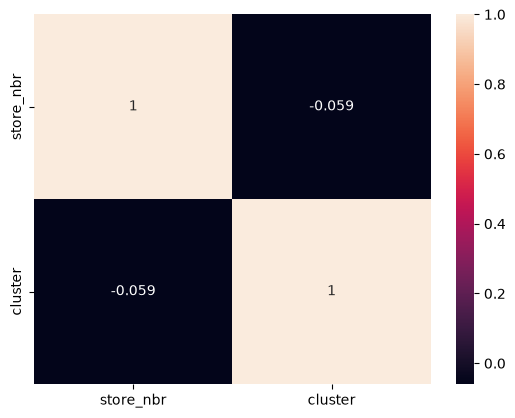

In [47]:
sns.heatmap(df.select_dtypes(include="number").corr(),annot=True)

### OUTLIERS

/tmp/ipykernel_3376/495366478.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns="store_nbr",inplace=True)


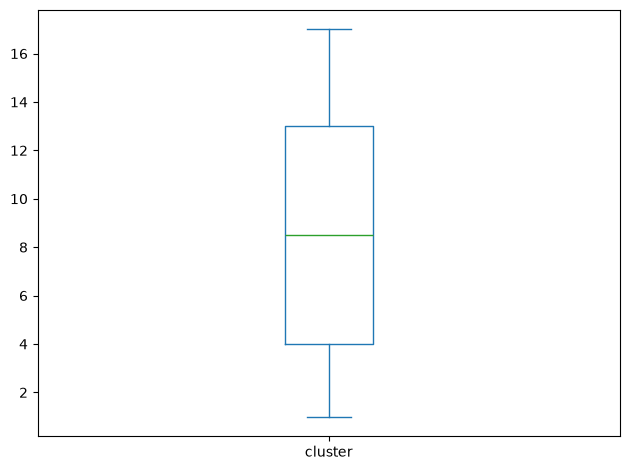

In [48]:
df.drop(columns="store_nbr",inplace=True)
df.select_dtypes(include="number").plot(kind="box",subplots=True,sharex=False,sharey=False)
plt.tight_layout()
plt.show()

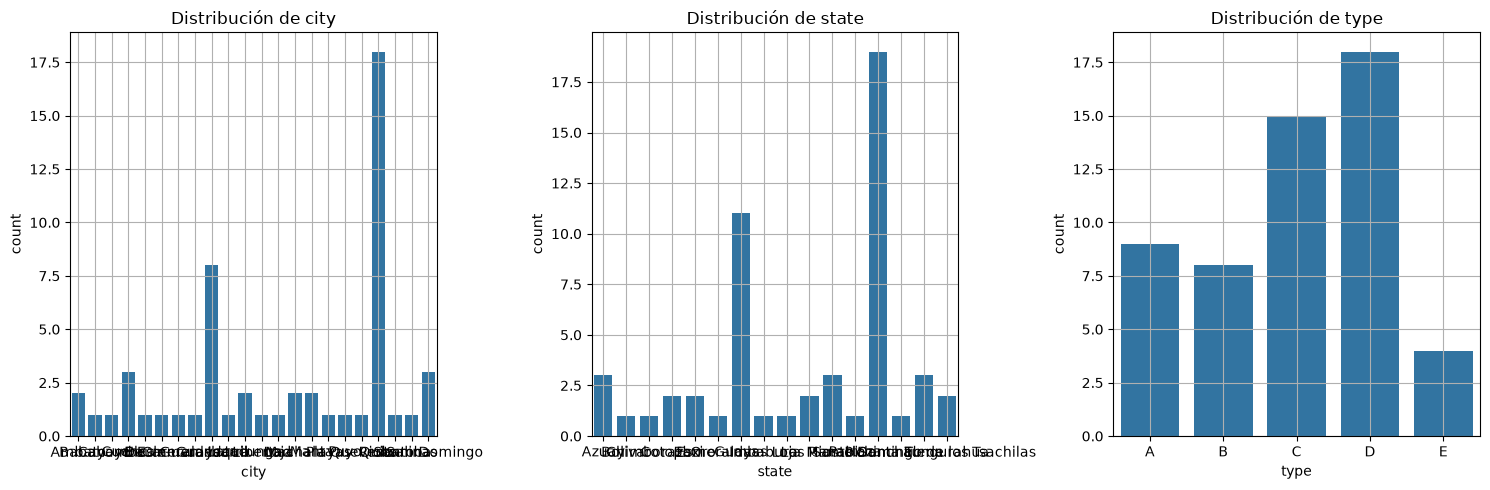

In [49]:
fig,ax=plt.subplots(1,3,figsize=(15,5))

for i ,col in enumerate(df.select_dtypes(include="category").columns):
    sns.countplot(data=df,x=col,ax=ax[i])
    ax[i].set_title(f"Distribución de {col}")
    ax[i].grid()
plt.tight_layout()
plt.show()

## EDA LIMPIEZA

### CLUSTER

<Axes: xlabel='cluster', ylabel='Count'>

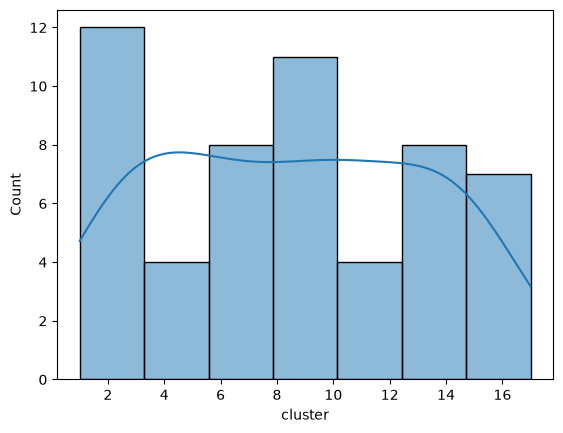

In [50]:
sns.histplot(data=df,x="cluster",kde=True)

In [51]:
print(f"Promedio de Cluster: {df["cluster"].mean():.2f}")
print(f"Median de Cluster: {df["cluster"].median():.2f}")

Promedio de Cluster: 8.48
Median de Cluster: 8.50


In [52]:
print(f"Curtosis: {df["cluster"].kurt():.2f}")
print(f"Asimetria: {df["cluster"].skew():.2f}")

Curtosis: -1.26
Asimetria: 0.04


### CITY

In [53]:
 df.groupby("city")["cluster"].sum().div(df["cluster"].sum()).mul(100).round(2).sort_values(ascending=False)

city
Quito            42.79
Guayaquil        13.10
Latacunga         6.55
Manta             5.24
Ambato            5.02
Ibarra            3.28
Guaranda          3.28
Santo Domingo     2.84
Libertad          2.18
Cuenca            2.18
Babahoyo          2.18
Esmeraldas        2.18
Riobamba          1.53
Machala           1.53
Puyo              1.53
Cayambe           1.31
Loja              0.87
El Carmen         0.66
Quevedo           0.66
Playas            0.66
Daule             0.22
Salinas           0.22
Name: cluster, dtype: float64

Text(0.5, 1.0, 'CONTEO')

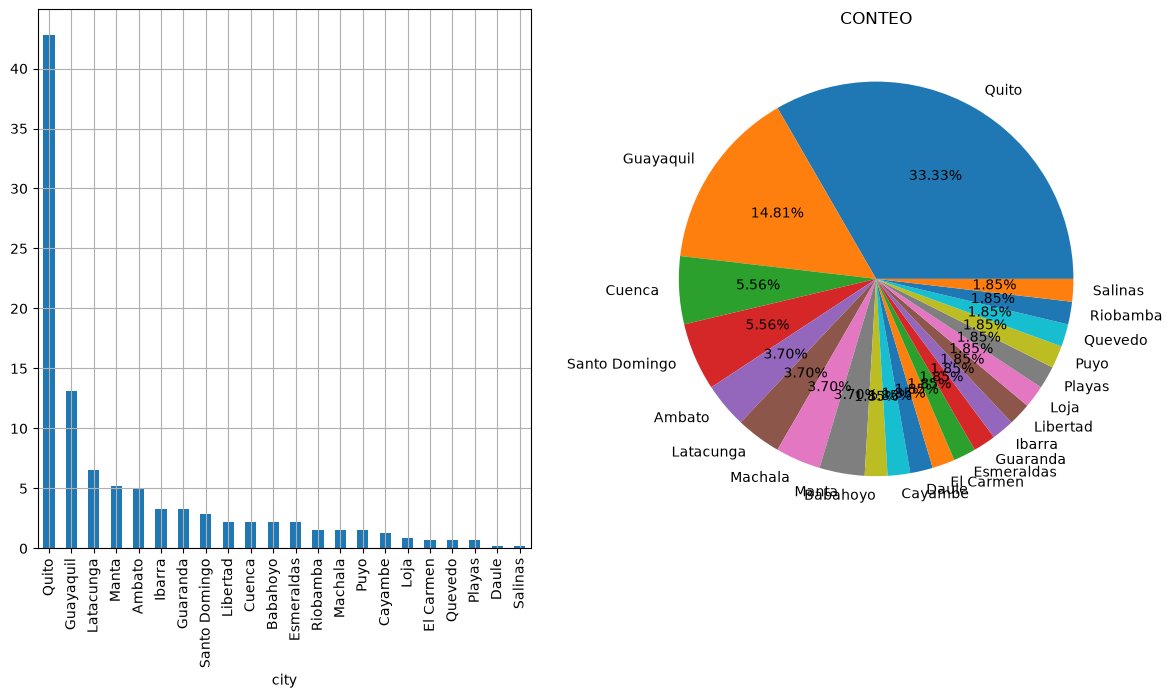

In [54]:
fig,ax=plt.subplots(1,2,figsize=(14,7))
df.groupby("city")["cluster"].sum().div(df["cluster"].sum()).mul(100).round(2).sort_values(ascending=False).plot(kind="bar",ax=ax[0])
ax[0].grid()
df["city"].value_counts().plot(kind="pie",autopct="%.2f%%",ax=ax[1])
ax[1].grid()
ax[1].set_title('CONTEO')

### STATE 

In [55]:
 df.groupby("state")["cluster"].sum().div(df["cluster"].sum()).mul(100).round(2).sort_values(ascending=False)

state
Pichincha                         44.10
Guayas                            16.16
Cotopaxi                           6.55
Manabi                             5.90
Tungurahua                         5.02
Imbabura                           3.28
Bolivar                            3.28
Los Rios                           2.84
Santo Domingo de los Tsachilas     2.84
Esmeraldas                         2.18
Azuay                              2.18
Chimborazo                         1.53
El Oro                             1.53
Pastaza                            1.53
Loja                               0.87
Santa Elena                        0.22
Name: cluster, dtype: float64

Text(0.5, 1.0, 'CONTEO')

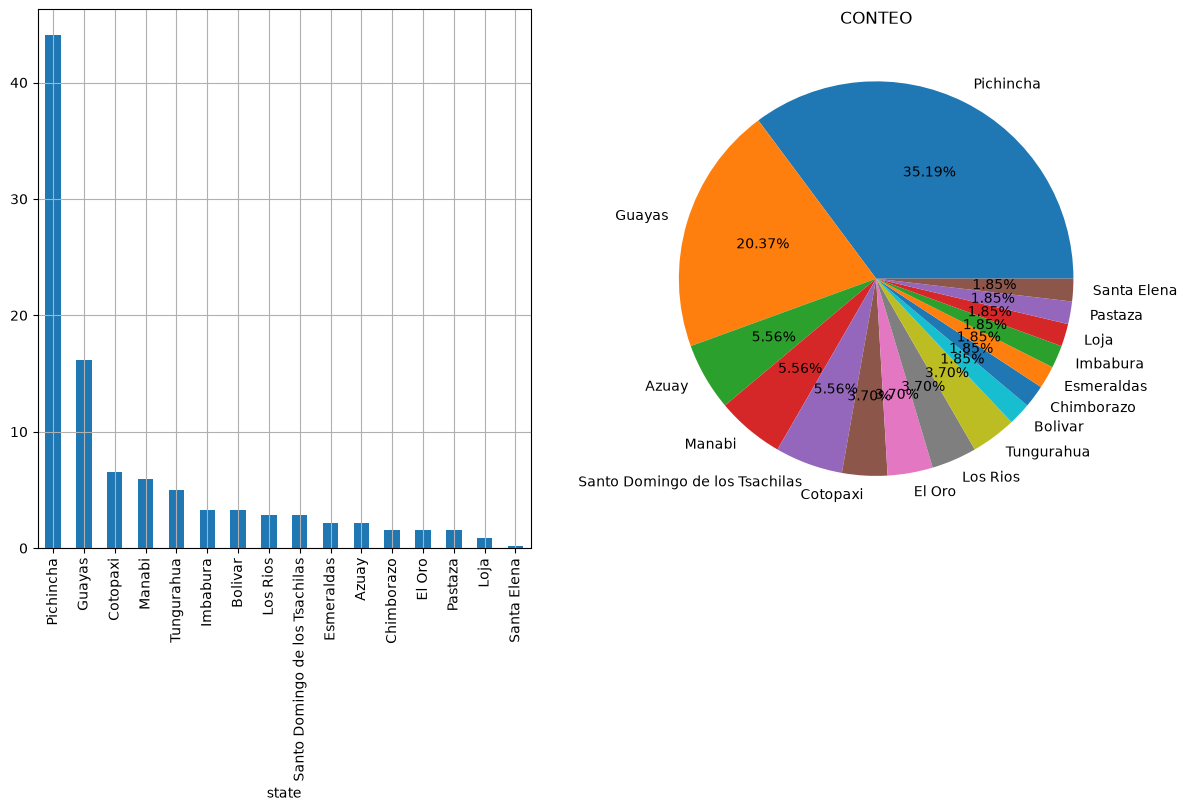

In [56]:
fig,ax=plt.subplots(1,2,figsize=(14,7))
df.groupby("state")["cluster"].sum().div(df["cluster"].sum()).mul(100).round(2).sort_values(ascending=False).plot(kind="bar",ax=ax[0])
ax[0].grid()
df["state"].value_counts().plot(kind="pie",autopct="%.2f%%",ax=ax[1])
ax[1].grid()
ax[1].set_title('CONTEO')

### TYPE

In [57]:
df.groupby("type")["cluster"].sum().div(df["cluster"].sum()).mul(100).round(2).sort_values(ascending=False)

type
D    26.86
C    26.64
A    24.24
B    13.54
E     8.73
Name: cluster, dtype: float64

Text(0.5, 1.0, 'CONTEO')

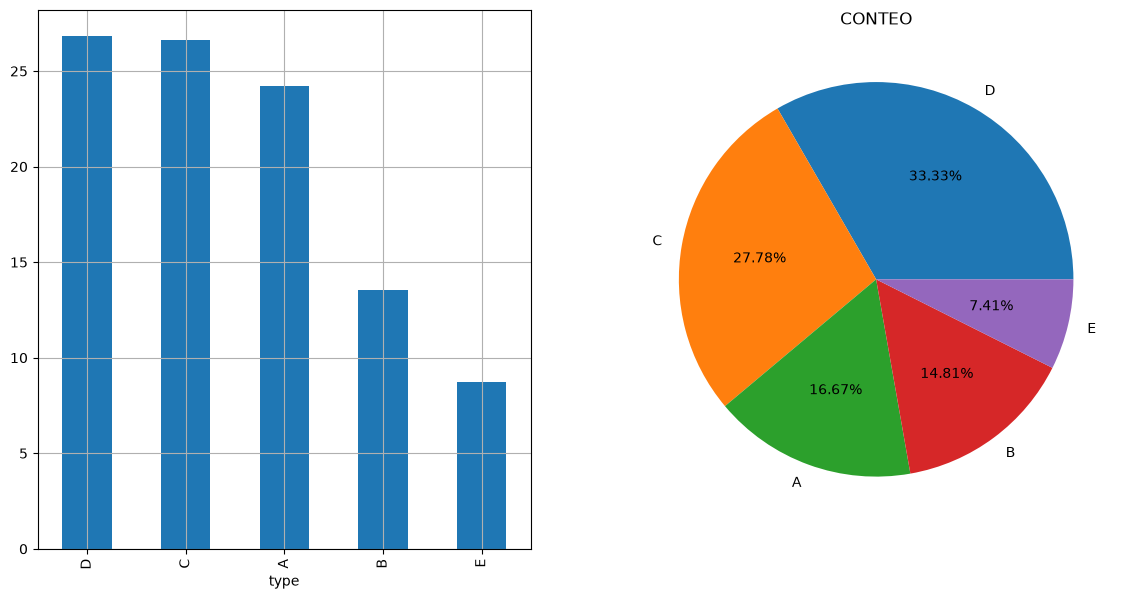

In [58]:
fig,ax=plt.subplots(1,2,figsize=(14,7))
df.groupby("type")["cluster"].sum().div(df["cluster"].sum()).mul(100).round(2).sort_values(ascending=False).plot(kind="bar",ax=ax[0])
ax[0].grid()
df["type"].value_counts().plot(kind="pie",autopct="%.2f%%",ax=ax[1])
ax[1].grid()
ax[1].set_title('CONTEO')

### GUARDAR 

In [59]:
df.to_csv("../data/silver/stores.csv",index=False,encoding="utf-8-sig")